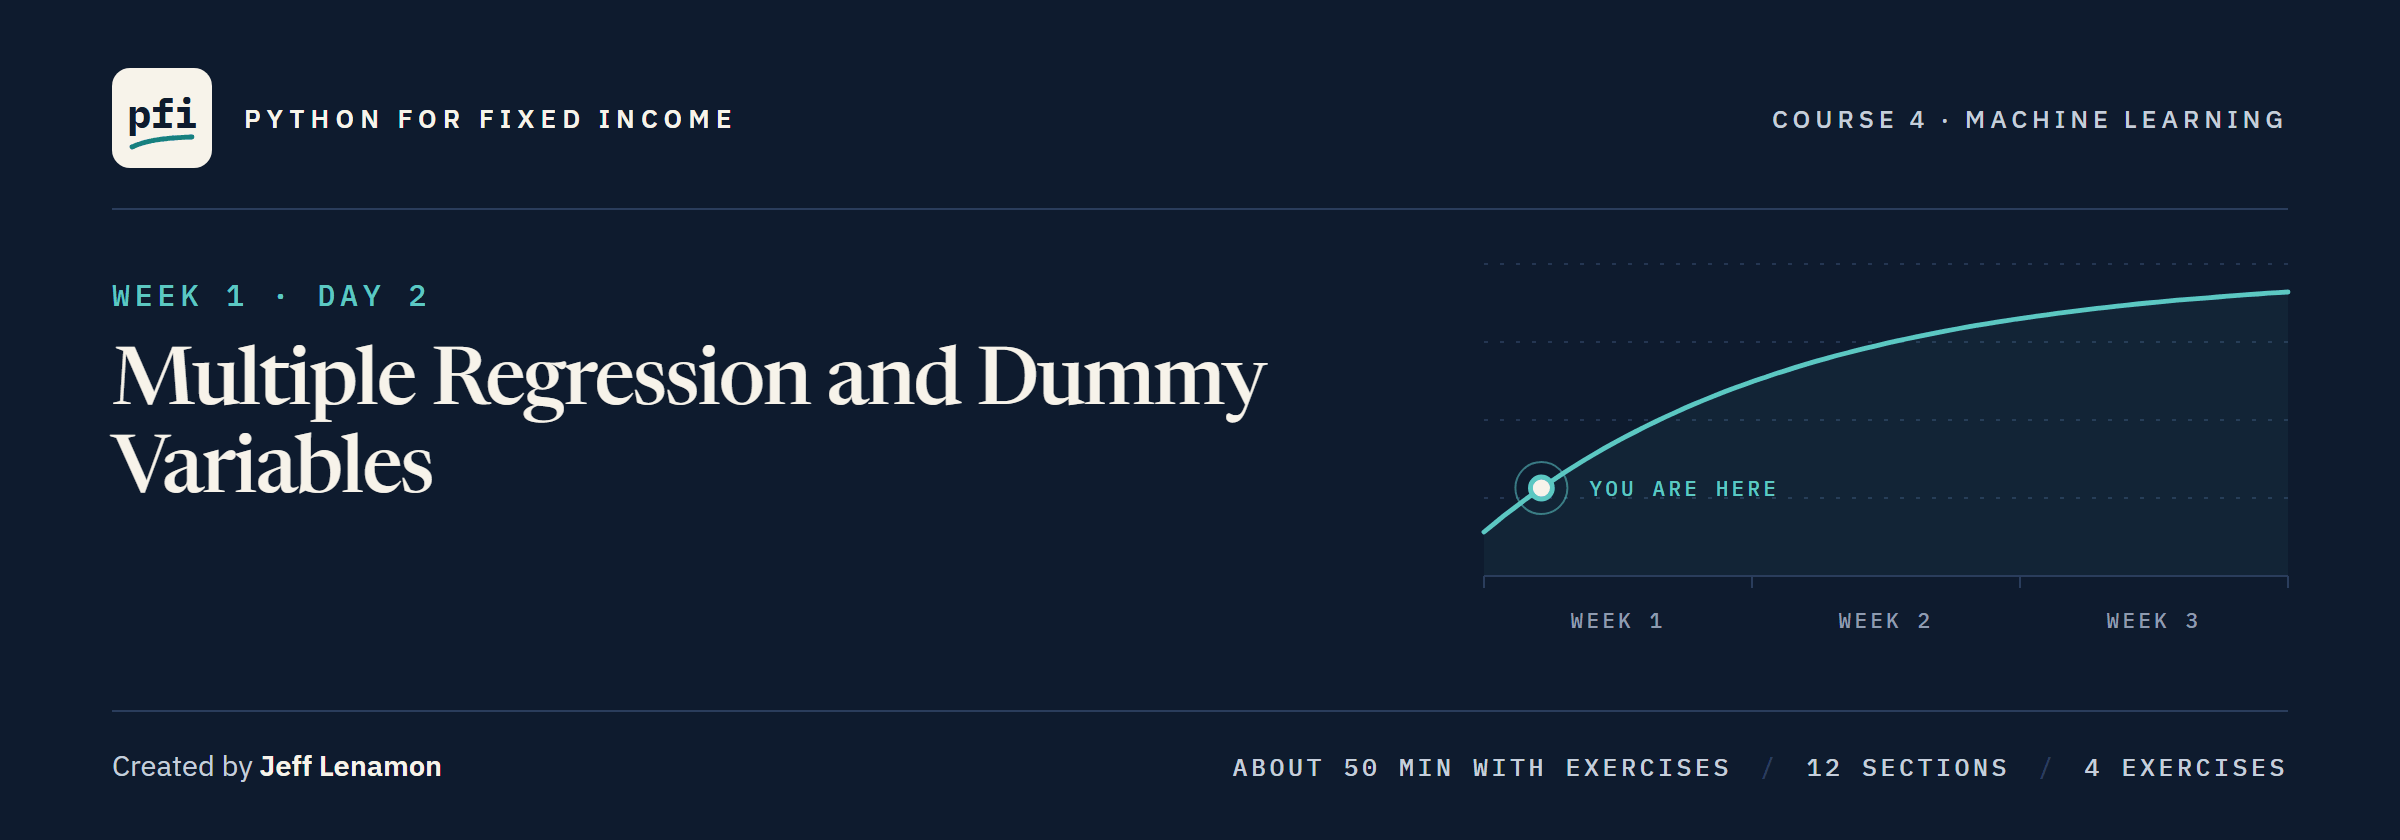

# Multiple Regression and Dummy Variables

Week 1, Day 2. Fit multiple regressions of a bond's spread, give every rating its own step, and score each model on bonds it has never seen.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day2/02_multiple_regression_and_dummy_variables.ipynb)

# Problem Statement

## Business Context

Day 1's rating line missed a typical unseen bond by 57.7 bp.
It also gave a AAA bond a fitted spread of -140 bp, because it takes the same 39 bp step at every notch.
The credit team now asks two questions.
Does a second column help the rating, and does the rating work better read as a label than as a number?
The bonds and issuers are invented for this course.

## Objectives

Fit multiple linear regressions of OAS: on rating score and duration, on one column per rating and duration, then with sector added.
Read every coefficient as a difference from a level you name, score each model in bp on the 206 test bonds, and choose one to carry forward.

## Data Dictionary

`benchmark.csv`, one row per bond:

1. `cusip`: the bond's identifier
2. `issuer`: the issuer's name
3. `sector`: one of 10 industry sectors, used for the first time today
4. `rating`: credit rating, AAA to CCC
5. `oas`: option-adjusted spread, bp, **the target**
6. `duration`: modified duration, years
7. `amount_outstanding`: face value outstanding, dollars (Exercise 1)

The file's other columns are not used today.

`ratings.csv` adds `score` (1 for AAA up to 18 for CCC) and `grade` (Investment Grade or High Yield).

## Your Route Through Day 2

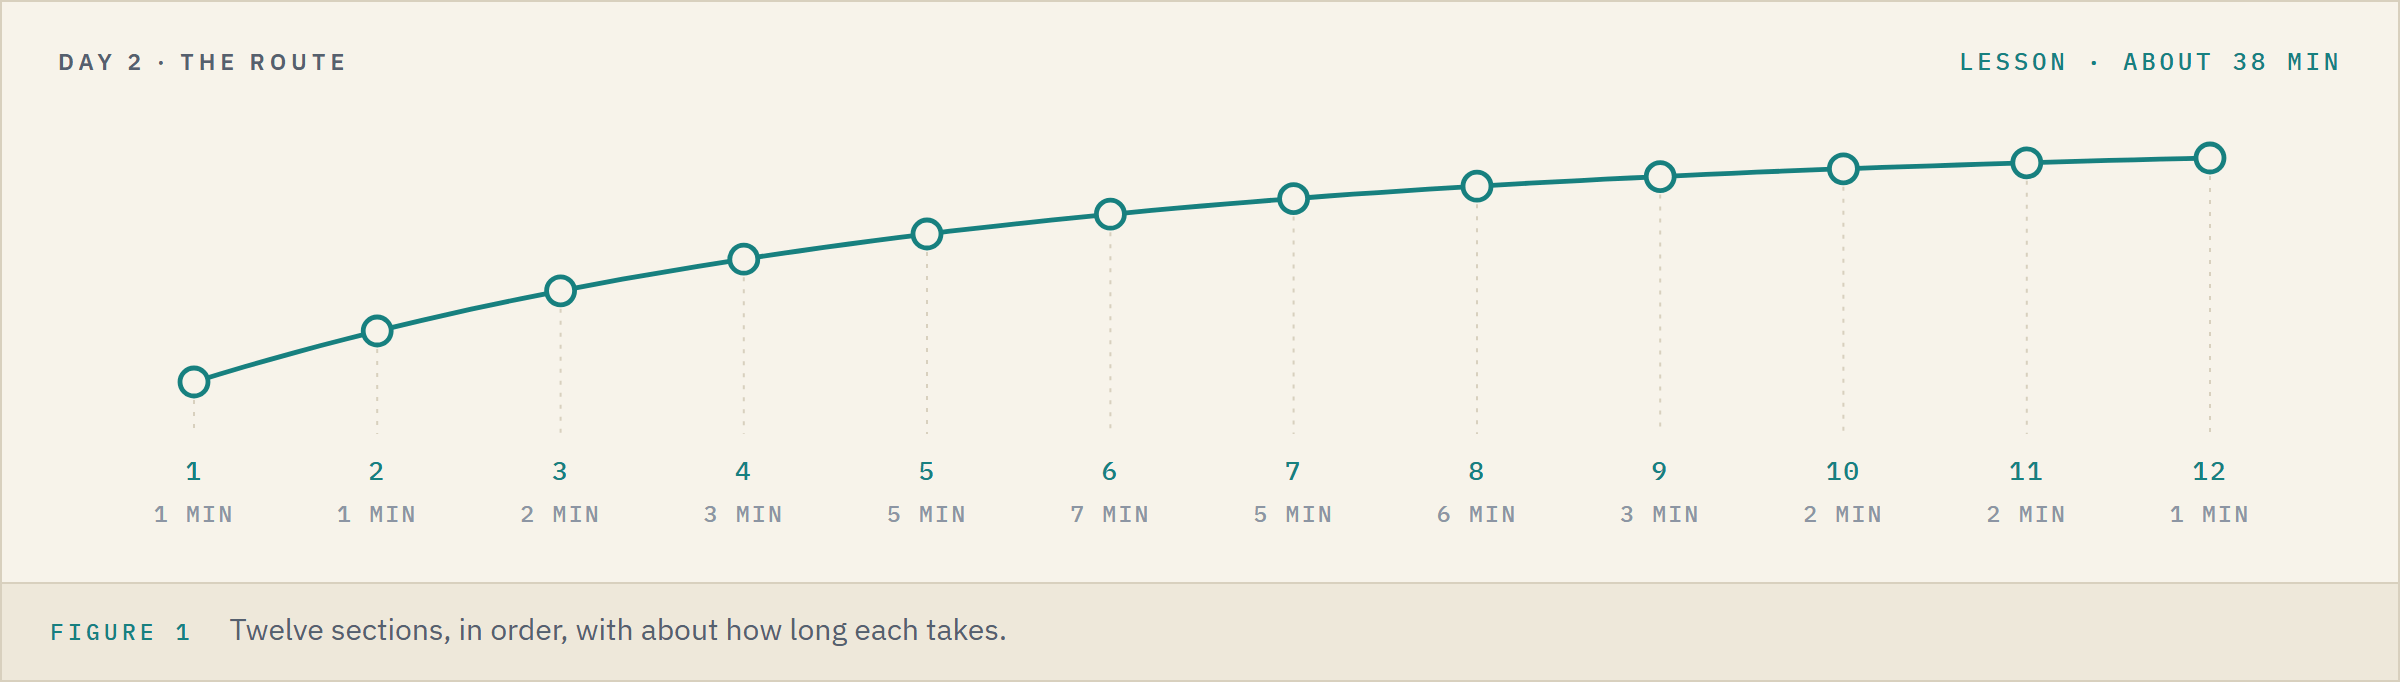

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">1</td><td align="left">Setting Up</td><td align="left">1 min</td></tr>
<tr><td align="left">2</td><td align="left">Loading the Data</td><td align="left">1 min</td></tr>
<tr><td align="left">3</td><td align="left">Data Overview</td><td align="left">2 min</td></tr>
<tr><td align="left">4</td><td align="left">Exploratory Data Analysis</td><td align="left">3 min</td></tr>
<tr><td align="left">5</td><td align="left">Data Preparation for Modeling</td><td align="left">5 min</td></tr>
<tr><td align="left">6</td><td align="left">Model Building</td><td align="left">7 min</td></tr>
<tr><td align="left">7</td><td align="left">Model Performance Evaluation</td><td align="left">5 min</td></tr>
<tr><td align="left">8</td><td align="left">Reading the Rating Steps</td><td align="left">6 min</td></tr>
<tr><td align="left">9</td><td align="left">Adding Sector</td><td align="left">3 min</td></tr>
<tr><td align="left">10</td><td align="left">Model Performance Comparison</td><td align="left">2 min</td></tr>
<tr><td align="left">11</td><td align="left">Residual Analysis</td><td align="left">2 min</td></tr>
<tr><td align="left">12</td><td align="left">Insights and Conclusion</td><td align="left">1 min</td></tr>
</table>
<br clear="left">

**Time.** About 38 minutes for the lesson, then about 12 for the four exercises.

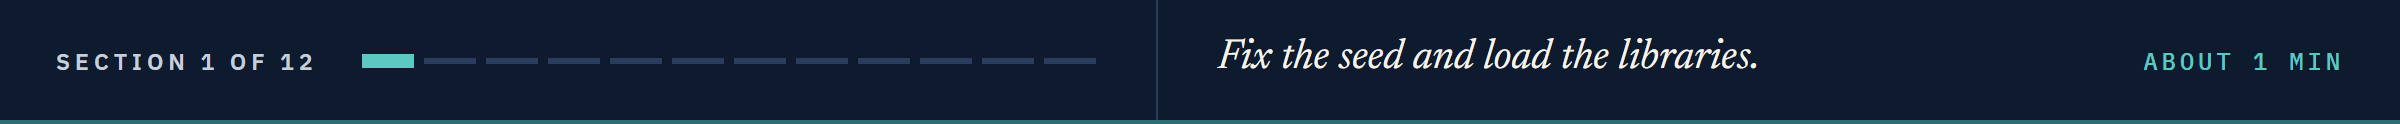

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# to split the bonds, fit linear regressions, and score them
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# one look for every chart, and plain numbers with three decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.3f}".format)

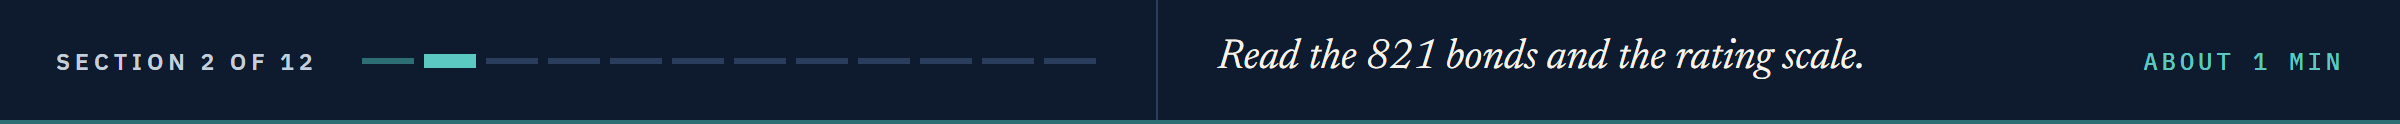

# Loading the Data

## Reading the Bonds and the Rating Scale

In [3]:
# the 821 bonds, and the table that turns each rating into a score and a grade
bonds = pd.read_csv(DATA + "benchmark.csv")
ratings = pd.read_csv(DATA + "ratings.csv")
data = bonds.merge(ratings[["rating", "score", "grade"]], on="rating")

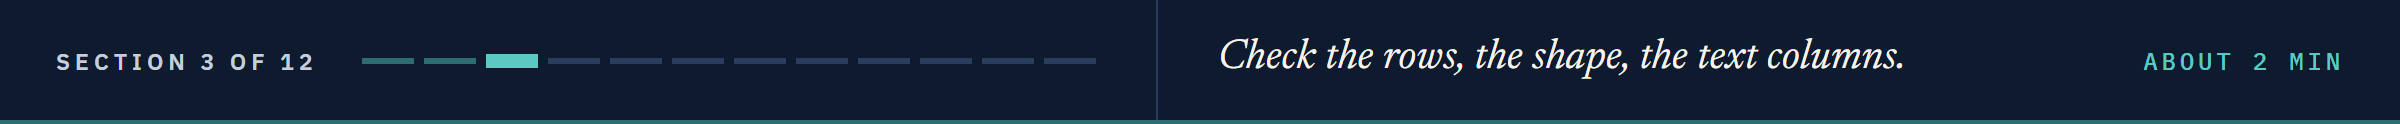

# Data Overview

## Checking the First Five Rows

Q. Which of today's columns hold text?

In [4]:
# the columns today's models use
data[["cusip", "issuer", "sector", "rating", "oas", "duration", "score", "grade"]].head()

,cusip,issuer,sector,rating,oas,duration,score,grade
0,99001BAA4,Quorvane Energy,Energy,BBB,83,6.000,9,Investment Grade
1,99001BAB2,Quorvane Energy,Energy,BBB,122,6.834,9,Investment Grade
2,99001BAC0,Quorvane Energy,Energy,BBB,123,9.848,9,Investment Grade
3,99001BAD8,Quorvane Energy,Energy,BBB,88,0.933,9,Investment Grade
4,99001BAE6,Quorvane Energy,Energy,BBB,127,6.256,9,Investment Grade


`sector` and `rating` are text; `score` is the rating as a number, Day 1's way.

## Checking the Shape and the Text Columns

Q. How many bonds, and how many different values does each text column hold?

In [5]:
# the number of bonds and columns, then the number of different ratings and sectors
print(data.shape)
data[["rating", "sector"]].nunique()

(821, 21)


rating    18
sector    10
dtype: int64

821 bonds and 21 columns, the file Day 1 checked: complete, with each bond in it once.

18 ratings and 10 sectors.

**Both text columns go into a model today, so first we look at how spread moves across their levels.**

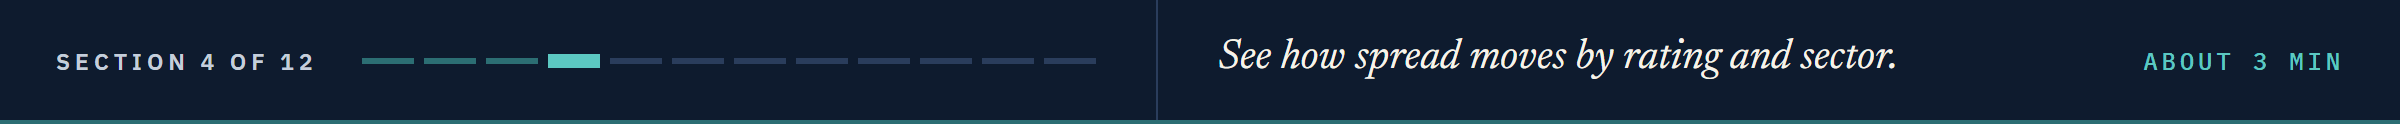

# Exploratory Data Analysis

Day 1's line adds the same 39 bp at every notch.

The first chart measures the steps the bonds actually take.

## Bivariate Analysis

### The Step From One Rating to the Next

Q. How many bp does the median spread add from each rating to the next?

In [6]:
# the median OAS of each rating in bp, AAA first, and the change from the rating above
rating_order = ratings["rating"]
median_oas = data.groupby("rating")["oas"].median()[rating_order]
steps = median_oas.diff().dropna()

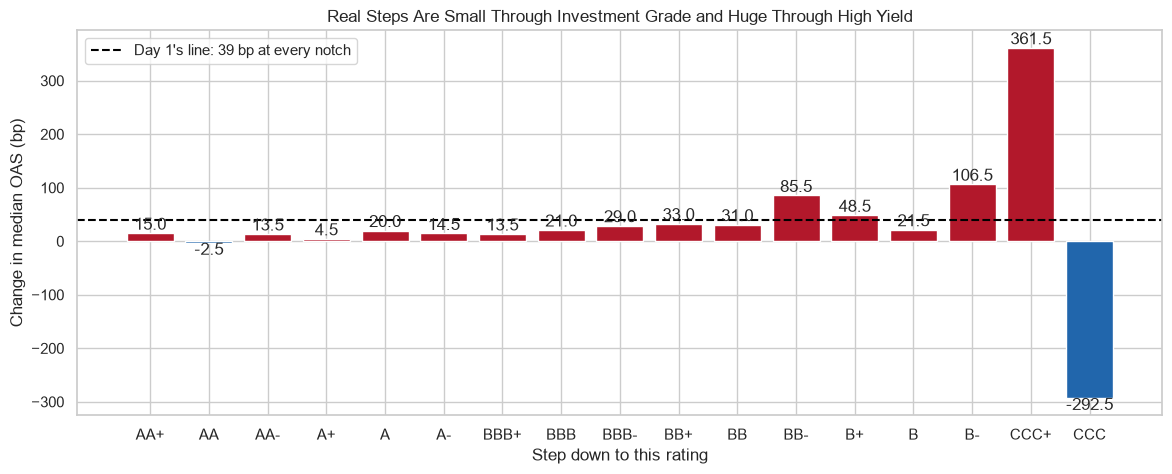

In [7]:
# one bar per step: red where the spread widens, blue where it tightens
colours = ["#B2182B" if step > 0 else "#2166AC" for step in steps]
plt.figure(figsize=(14, 5))
bars = plt.bar(steps.index, steps, color=colours)
plt.bar_label(bars, fmt="%.1f")  # each bar labelled with its step in bp
plt.axhline(39.05, color="black", linestyle="--", label="Day 1's line: 39 bp at every notch")
plt.xlabel("Step down to this rating")
plt.ylabel("Change in median OAS (bp)")
plt.title("Real Steps Are Small Through Investment Grade and Huge Through High Yield")
plt.legend()
plt.show()

From AA- down to BB every step is between 4.5 and 33 bp, all below Day 1's 39.

Then the steps grow: 85.5 bp into BB-, 106.5 into B-, 361.5 into CCC+.

The two blue bars, AA and CCC, sit on levels with 5 and 3 bonds.

### OAS by Sector

Q. Do spreads differ from one sector to another?

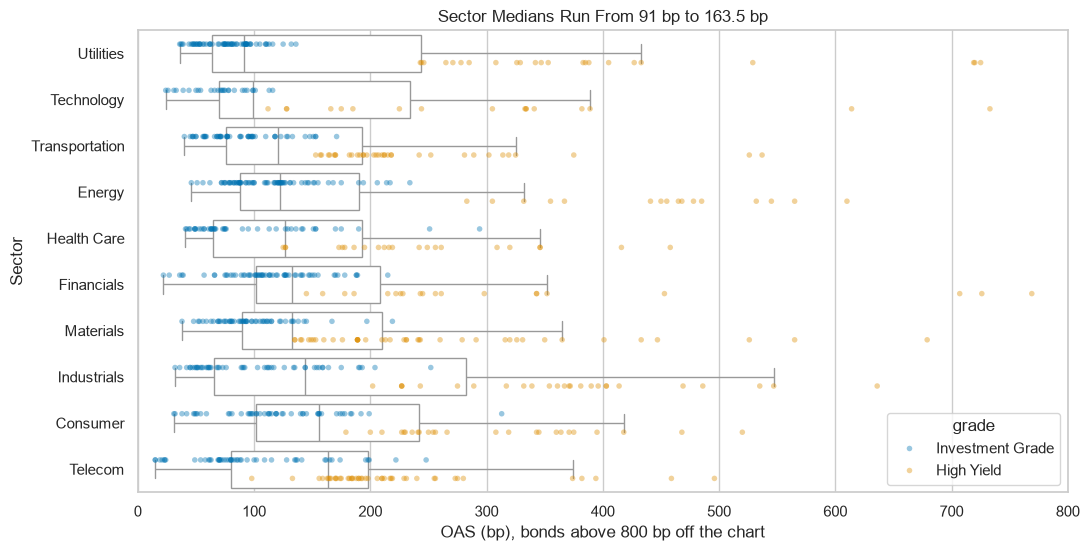

In [8]:
# sectors in order of their median spread, tightest at the top
sector_order = data.groupby("sector")["oas"].median().sort_values().index

# one box per sector, with every bond drawn on top, coloured by grade
# jitter=False: no random shuffle of the dots, so every run draws the same chart; dodge=True: one line per grade
plt.figure(figsize=(12, 6))
sns.boxplot(data=data, x="oas", y="sector", order=sector_order, color="white", showfliers=False)
sns.stripplot(data=data, x="oas", y="sector", order=sector_order, hue="grade", alpha=0.4, size=4,
              jitter=False, dodge=True)
plt.xlim(0, 800)
plt.xlabel("OAS (bp), bonds above 800 bp off the chart")
plt.ylabel("Sector")
plt.title("Sector Medians Run From 91 bp to 163.5 bp")
plt.show()

Median spreads run from 91 bp (Utilities) to 163.5 bp (Telecom).

Every sector mixes investment grade and high yield bonds, so part of each gap may be its rating mix.

**One slope cannot follow steps this uneven, so each rating gets its own step; sector may matter too, so it gets columns as well.**

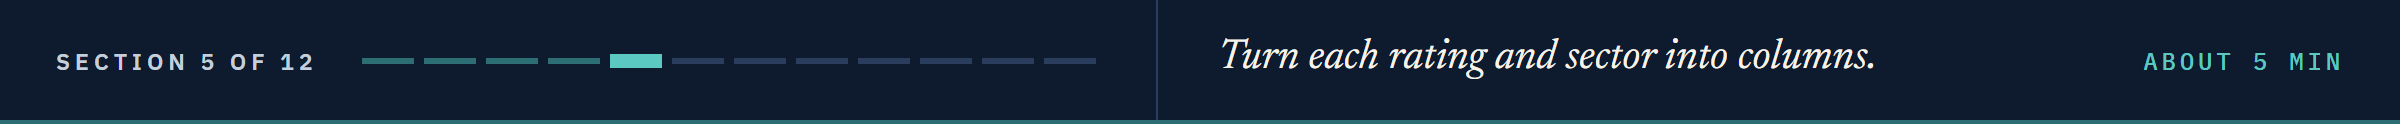

# Data Preparation for Modeling

## Dummy Variables: A Category as Columns

A model can only multiply numbers, so a text column must become numbers first.

A **dummy variable**, or indicator column, holds 1.0 for a bond with one level and 0.0 for every other bond.

One of them is then left out: the **reference level**, the level every other step is measured from, which the intercept stands for.

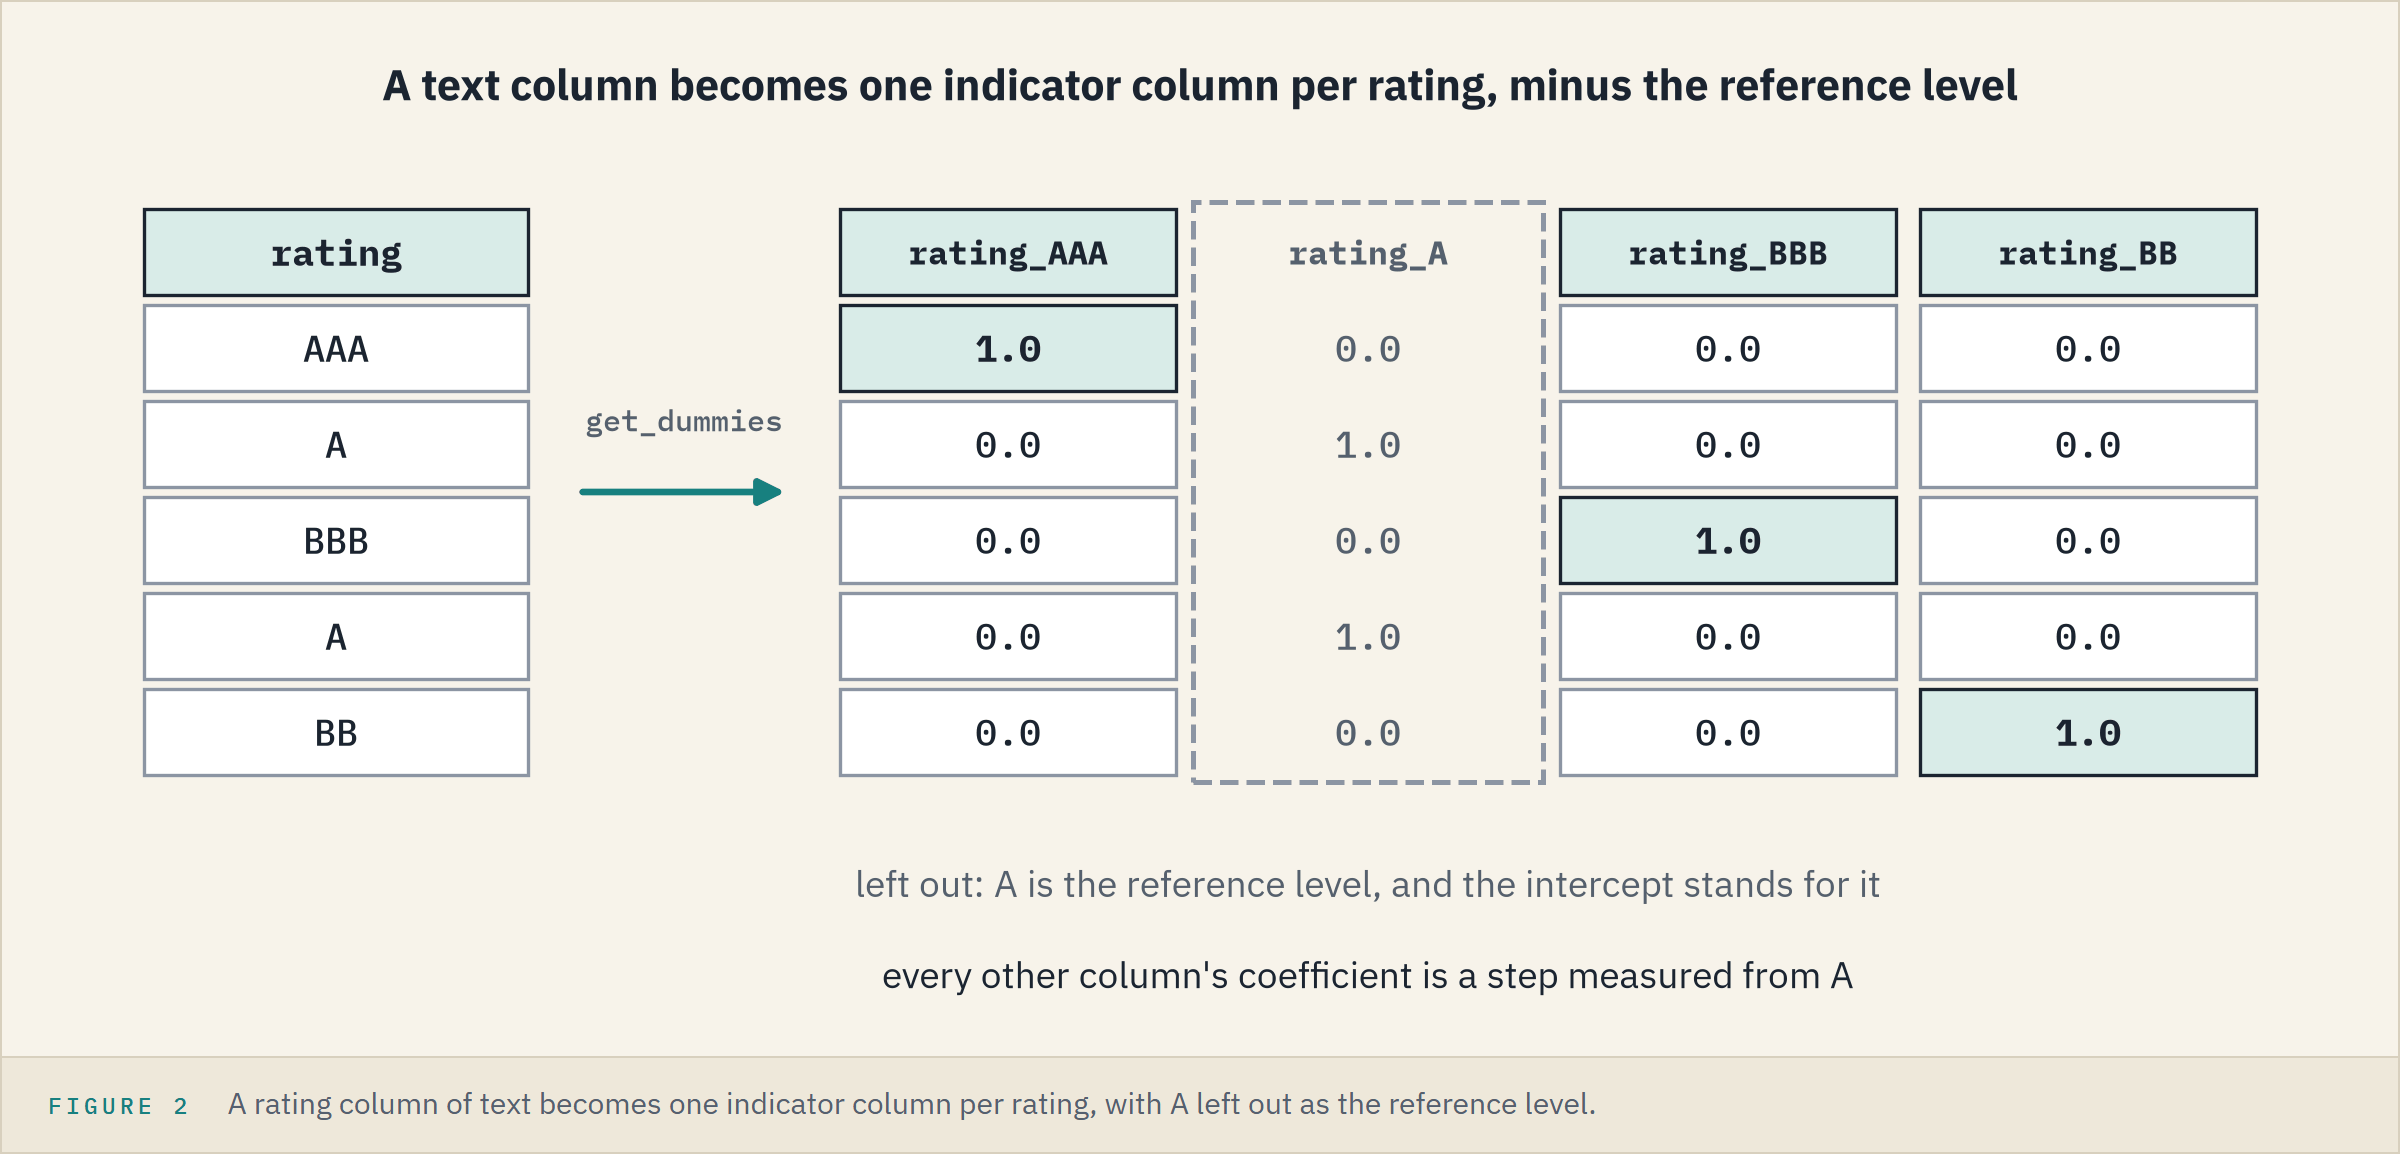

`pd.Categorical(..., categories=)`, from Course 1, keeps the columns in rating order, AAA first.

`pd.get_dummies` makes one column per level, and `dtype=float` makes the columns numbers.

In [9]:
# the rating as a category in scale order, so the columns run AAA to CCC
rating_category = pd.Categorical(data["rating"], categories=rating_order)

# one indicator column per rating: 1.0 for a bond with that rating, 0.0 otherwise
all_ratings = pd.get_dummies(rating_category, prefix="rating", dtype=float)
all_ratings.shape

(821, 18)

## Naming the Reference Level

We leave out A.

It sits in the middle of investment grade, it has plenty of bonds, and "the difference from a single-A bond" is easy to say on a desk.

In [10]:
# leave out the A column: A becomes the reference level
rating_dummies = all_ratings.drop(columns="rating_A")
list(rating_dummies.columns)

['rating_AAA',
 'rating_AA+',
 'rating_AA',
 'rating_AA-',
 'rating_A+',
 'rating_A-',
 'rating_BBB+',
 'rating_BBB',
 'rating_BBB-',
 'rating_BB+',
 'rating_BB',
 'rating_BB-',
 'rating_B+',
 'rating_B',
 'rating_B-',
 'rating_CCC+',
 'rating_CCC']

### The Indicator Grid

Q. What do the 17 columns hold for one bond of each rating?

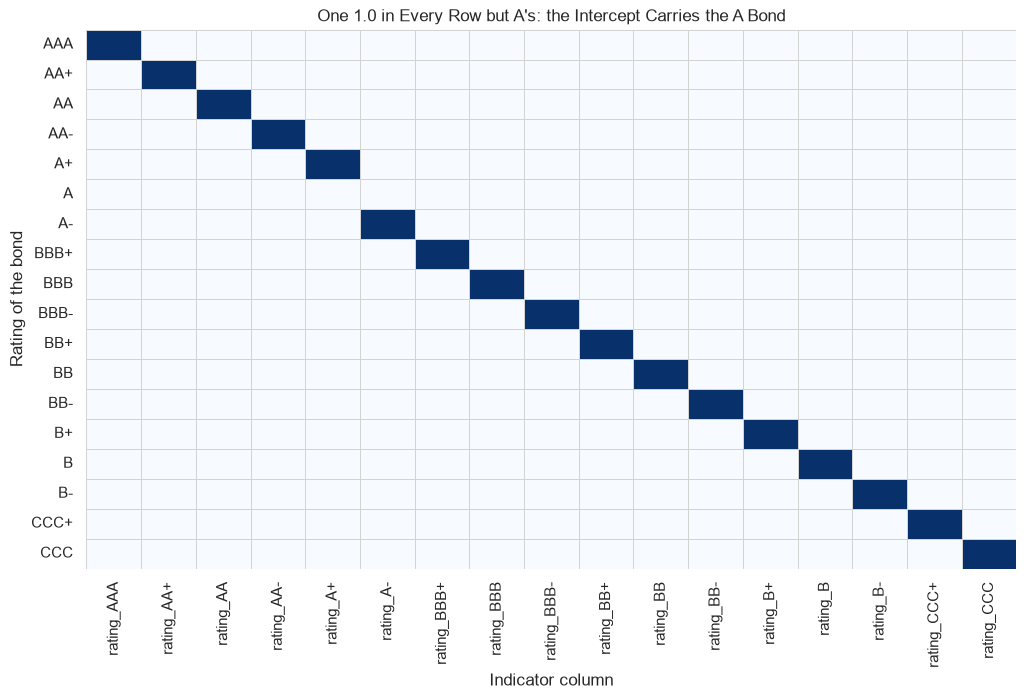

In [11]:
# one bond of each rating, AAA first
one_each = data.drop_duplicates("rating").sort_values("score")

# their 17 indicator columns: a dark square for each 1.0, thin gray lines between squares, each row named by its rating
plt.figure(figsize=(12, 7))
sns.heatmap(rating_dummies.loc[one_each.index], cmap="Blues", cbar=False, linewidths=0.5,
            linecolor="lightgray", yticklabels=one_each["rating"])
plt.xlabel("Indicator column")
plt.ylabel("Rating of the bond")
plt.title("One 1.0 in Every Row but A's: the Intercept Carries the A Bond")
plt.show()

Every row has exactly one 1.0, except the A bond's, which has none.

The 1.0s make a staircase with one stair missing.

## Sector Columns

The same two steps turn the sector into nine columns.

Consumer, first in alphabetical order, is the reference; any sector would do.

In [12]:
# one column per sector, Consumer left out as the reference level
sector_dummies = pd.get_dummies(data["sector"], prefix="sector", dtype=float)
sector_dummies = sector_dummies.drop(columns="sector_Consumer")
sector_dummies.shape

(821, 9)

## Choosing the Features and the Target

In [13]:
# every candidate column side by side, and the target: OAS in bp
X = pd.concat([data[["score", "duration"]], rating_dummies, sector_dummies], axis=1)
y = data["oas"]
X.shape

(821, 28)

## Splitting Into Training and Test Bonds

In [14]:
# hold back a quarter of the bonds; the seed makes the same split on every run
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=SEED)
print("Training bonds:", len(X_train), " Test bonds:", len(X_test))

Training bonds: 615  Test bonds: 206


615 and 206: the same bonds as Day 1, because the split depends only on the number of rows and the seed.

**Every column is now a number, and the test bonds are put away exactly as on Day 1.**

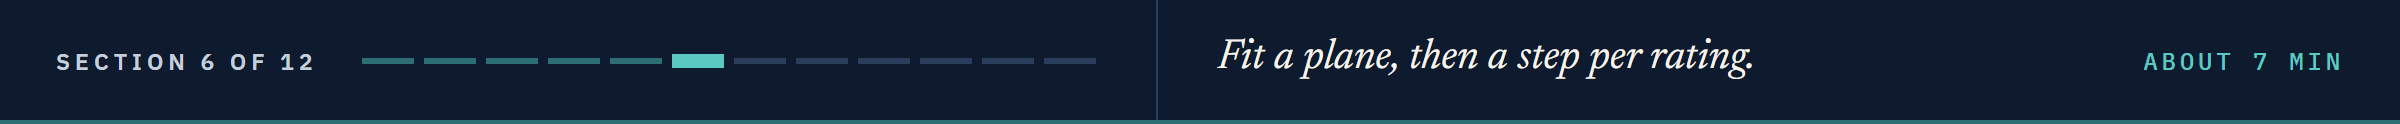

# Model Building

## Multiple Linear Regression - OAS vs Rating Score and Duration

A **multiple linear regression** fits one coefficient per feature, all together, plus an intercept.

Each coefficient is the change in fitted spread for one unit of its feature, **holding the other features fixed**.

In [15]:
# two features this time: the rating score and the duration
features_score = ["score", "duration"]

# create an empty linear regression model, then fit it to the training bonds
model_score = LinearRegression()
model_score.fit(X_train[features_score], y_train)

# the fitted model, written as an equation: one coefficient per feature
b_score, b_duration = model_score.coef_
print("OAS = (", round(b_score, 2), ") * score + (", round(b_duration, 2), ") * duration + (",
      round(model_score.intercept_, 2), ")")

OAS = ( 39.14 ) * score + ( 0.87 ) * duration + ( -185.03 )


### The Fitted Plane

With two features the line becomes a **fitted plane**: one height of fitted spread for every pair of score and duration.

`add_subplot(projection="3d")` gives a chart a third axis, and `plot_surface` draws a sheet over a grid made by `np.meshgrid`, from Course 1.

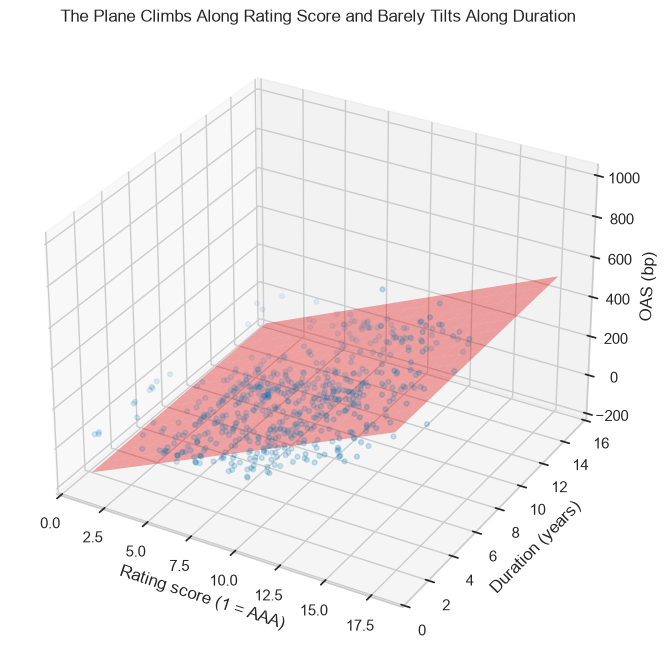

In [16]:
# a grid of scores and durations, and the plane's fitted spread at every point of it
score_grid, duration_grid = np.meshgrid(np.arange(1, 19), np.linspace(1, 15, 15))
plane = model_score.intercept_ + b_score * score_grid + b_duration * duration_grid

# the training bonds below 1,000 bp as dots, the plane as a red sheet
shown = y_train < 1000
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")
ax.scatter(X_train.loc[shown, "score"], X_train.loc[shown, "duration"], y_train[shown], s=12, alpha=0.5)
ax.plot_surface(score_grid, duration_grid, plane, color="red", alpha=0.35, linewidth=0)
ax.set_xlabel("Rating score (1 = AAA)")
ax.set_ylabel("Duration (years)")
ax.set_zlabel("OAS (bp)")
ax.set_title("The Plane Climbs Along Rating Score and Barely Tilts Along Duration")
plt.show()

### Interpretation of the Coefficients

Holding duration fixed, one notch down the scale goes with 39.14 bp more fitted spread (Day 1's line: 39.05).

Holding the score fixed, one more year of duration goes with 0.87 bp more.

Across the plane's 1 to 15 years, that moves the fitted spread by only about 12 bp.

**The plane is Day 1's line tilted a hair along duration, so next every rating gets a step of its own.**

## Multiple Linear Regression - OAS vs Rating Dummies and Duration

In [17]:
# the 17 rating columns and duration
features_steps = list(rating_dummies.columns) + ["duration"]

# create the model and fit it to the training bonds
model_steps = LinearRegression()
model_steps.fit(X_train[features_steps], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](18,)","[-48.99,-47.19,-38.62,...,828.67,458.08, 2.66]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](18,)","['rating_AAA','rating_AA+','rating_AA',...,'rating_CCC+','rating_CCC', 'duration']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,59.65
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,18
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(18)


In [18]:
# each rating's step from A in bp, beside the number of training bonds with that rating
coefficients = pd.Series(model_steps.coef_, index=features_steps)
step_table = pd.DataFrame({"step from A (bp)": coefficients[rating_dummies.columns],
                           "training bonds": X_train[rating_dummies.columns].sum().astype(int)})
print("Intercept:", round(model_steps.intercept_, 1), " Duration:", round(coefficients["duration"], 2))
step_table

Intercept: 59.7  Duration: 2.66


,step from A (bp),training bonds
rating_AAA,-48.992,11
rating_AA+,-47.188,4
rating_AA,-38.617,4
rating_AA-,-29.421,15
rating_A+,-19.245,56
rating_A-,15.421,80
rating_BBB+,25.150,57
rating_BBB,47.975,42
rating_BBB-,78.009,77
rating_BB+,114.613,64


### Interpretation of the Coefficients

The intercept, 59.7 bp, is the fitted spread of an A bond at duration 0: the reference level lives in the intercept.

Each rating coefficient is that rating's fitted difference from an A bond of the same duration: AAA 49.0 bp below, BBB 48.0 above, BB 164.4 above, CCC+ 828.7 above.

CCC sits 370.6 bp below CCC+ on 3 training bonds: a step fitted on three bonds is mostly those three bonds.

Duration's coefficient moves from 0.87 to 2.66 bp per year.
A coefficient is read beside the other columns in its model, so changing how the rating enters changes duration's too.

### One Bond's Fitted Spread, Step by Step

Q. How does the model build one bond's fitted spread?

A **waterfall chart** stacks the parts: each bar starts where the one before it ended (`bottom=`).

In [19]:
# one bond: Veyrholt Health 99006GAB6, rated BB, with 5.46 years of duration
bond = data[data["cusip"] == "99006GAB6"].iloc[0]

# its fitted spread as three parts, in bp
parts = pd.Series({"A bond at duration 0": model_steps.intercept_,
                   "BB step": coefficients["rating_BB"],
                   "5.46 years of duration": coefficients["duration"] * bond["duration"]})
parts

A bond at duration 0      59.653
BB step                  164.409
5.46 years of duration    14.535
dtype: float64

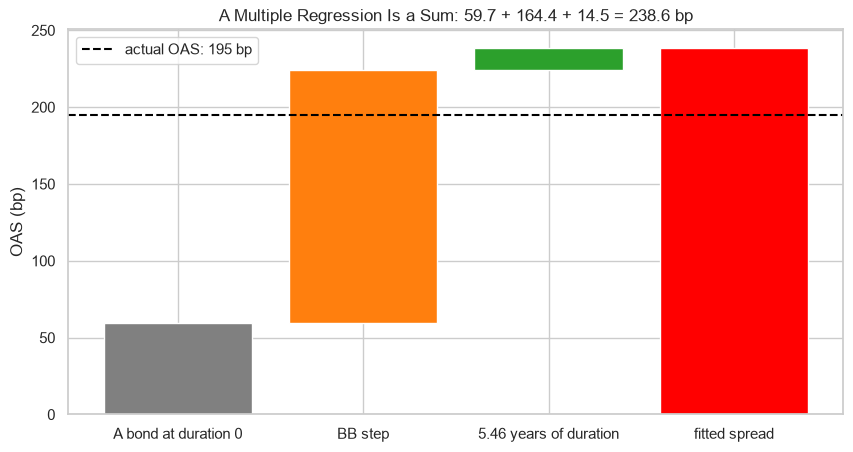

In [20]:
# a waterfall: each bar starts where the last one ended, then the total
starts = parts.cumsum() - parts
plt.bar(parts.index, parts, bottom=starts, color=["gray", "tab:orange", "tab:green"])
plt.bar("fitted spread", parts.sum(), color="red")
plt.axhline(bond["oas"], color="black", linestyle="--", label="actual OAS: 195 bp")
plt.ylabel("OAS (bp)")
plt.title("A Multiple Regression Is a Sum: 59.7 + 164.4 + 14.5 = 238.6 bp")
plt.legend()
plt.show()

The intercept, then one term per column: the bond's own rating step, and its duration times 2.66.

The bond's 16 other rating columns hold 0.0, so their steps add nothing.

The fitted spread is 238.6 bp; the bond's actual OAS is 195 bp.

## Equal Steps Against Free Steps

Q. Where do one 39 bp step and 17 free steps part company?

In [21]:
# one typical bond per rating: the 17 rating columns, the score, and the median training duration
typical = pd.get_dummies(pd.Categorical(rating_order, categories=rating_order), prefix="rating", dtype=float)
typical = typical.drop(columns="rating_A")
typical["score"] = ratings["score"]
typical["duration"] = X_train["duration"].median()

# each model's fitted spread for those 18 bonds, in bp
fitted_line = model_score.predict(typical[features_score])
fitted_steps = model_steps.predict(typical[features_steps])
train_rating = data.loc[X_train.index, "rating"]

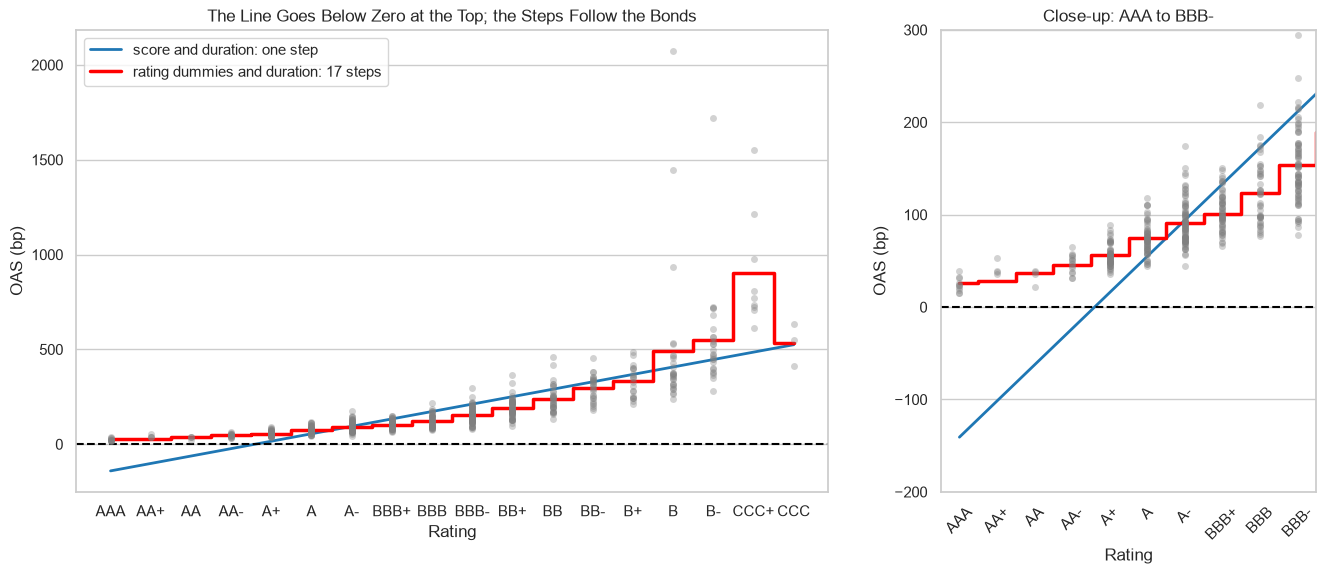

In [22]:
# two panels, the left twice as wide (width_ratios): the training bonds by rating, both models, and a close-up
fig, axes = plt.subplots(1, 2, figsize=(16, 6), width_ratios=[2, 1])
for ax in axes:
    sns.stripplot(x=train_rating, y=y_train, order=rating_order, color="gray", alpha=0.35, jitter=False, ax=ax)
    ax.plot(range(18), fitted_line, color="tab:blue", linewidth=2, label="score and duration: one step")
    # where="mid": each step changes halfway between two ratings
    ax.step(range(18), fitted_steps, where="mid", color="red", linewidth=2.5, label="rating dummies and duration: 17 steps")
    ax.axhline(0, color="black", linestyle="--")
    ax.set_xlabel("Rating")
    ax.set_ylabel("OAS (bp)")
axes[1].set_xlim(-0.5, 9.5)
axes[1].set_ylim(-200, 300)
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_title("Close-up: AAA to BBB-")
axes[0].set_title("The Line Goes Below Zero at the Top; the Steps Follow the Bonds")
axes[0].legend()
plt.show()

The straight line is below zero for the top four ratings; no step ever is.

Through high yield the steps bend upward as the bonds do, and the line falls short.

**The steps follow the bonds. Now both models face the test bonds.**

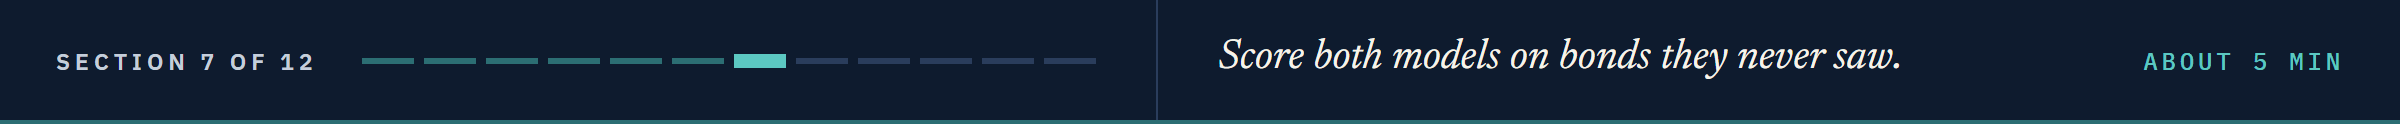

# Model Performance Evaluation

## The Scoring Function

Day 1's function, unchanged: five measures for one model on one set of bonds, in one row.

In [23]:
# MAPE: each miss as a percent of the actual spread, averaged
def mape_score(actual, fitted):
    return np.mean(np.abs(actual - fitted) / actual) * 100


# adjusted R-squared: R-squared with a charge for each feature
def adj_r2_score(predictors, actual, fitted):
    r2 = r2_score(actual, fitted)
    n = predictors.shape[0]  # number of bonds
    k = predictors.shape[1]  # number of features
    return 1 - (1 - r2) * (n - 1) / (n - k - 1)


# the five measures for one model on one set of bonds, as a one-row table
def model_performance_regression(model, predictors, target):
    fitted = model.predict(predictors)
    return pd.DataFrame({
        "RMSE": [np.sqrt(mean_squared_error(target, fitted))],
        "MAE": [mean_absolute_error(target, fitted)],
        "MAPE": [mape_score(target, fitted)],
        "R-squared": [r2_score(target, fitted)],
        "Adj. R-squared": [adj_r2_score(predictors, target, fitted)],
    })

## Scoring OAS vs Rating Score and Duration

In [24]:
# how the score and duration model does on the bonds it was fitted on
score_train_perf = model_performance_regression(model_score, X_train[features_score], y_train)
score_train_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,133.017,65.646,56.483,0.523,0.521


**Predict 1**

Day 1's rating line missed a typical test bond by 57.7 bp.

Write down this model's MAE on the 206 test bonds, in bp.

In [25]:
# how it does on bonds it has never seen
score_test_perf = model_performance_regression(model_score, X_test[features_score], y_test)
score_test_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,108.324,57.488,42.191,0.553,0.549


Test MAE 57.5 bp, RMSE 108.3 bp, R-squared 0.553: Day 1's line, give or take a fraction of a bp.

A second column helps only if it adds something the first lacks.

## Scoring OAS vs Rating Dummies and Duration

In [26]:
# the steps model on the bonds it was fitted on
steps_train_perf = model_performance_regression(model_steps, X_train[features_steps], y_train)
steps_train_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,110.177,42.710,21.219,0.673,0.663


**Predict 2**

On its training bonds the steps model misses by 42.7 bp on average.

Write down its MAE on the 206 test bonds, in bp.

In [27]:
# and on bonds it has never seen
steps_test_perf = model_performance_regression(model_steps, X_test[features_steps], y_test)
steps_test_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,69.135,35.539,19.785,0.818,0.800


Test MAE 35.5 bp, RMSE 69.1 bp, R-squared 0.818.

Test beats training again, as on Day 1: which side comes out lower is the luck of which bonds fell where.

## How Many Bonds Each Model Misses by Less Than X

An **ECDF** (empirical cumulative distribution function) plots, for every size of miss, the share of bonds missed by that much or less.

In [28]:
# each test bond's miss in bp under each model, ignoring the sign
misses = pd.DataFrame({
    "score and duration": (y_test - model_score.predict(X_test[features_score])).abs(),
    "rating dummies and duration": (y_test - model_steps.predict(X_test[features_steps])).abs(),
})

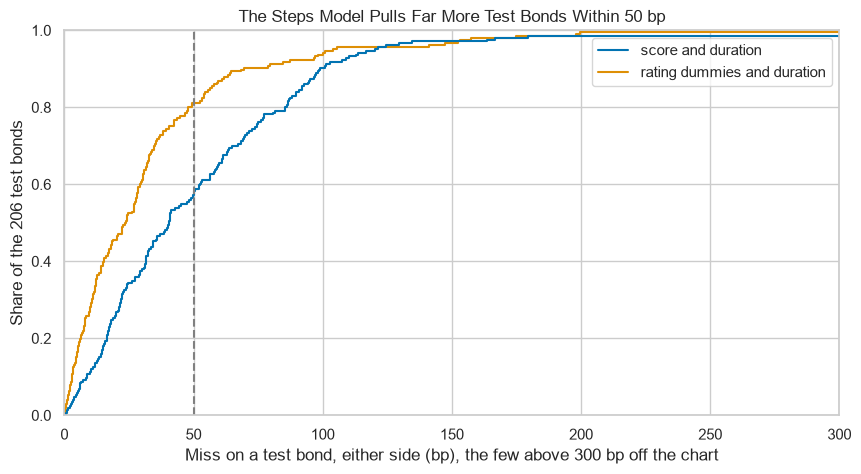

score and duration            0.573
rating dummies and duration   0.811
dtype: float64
score and duration            40.500
rating dummies and duration   23.500
dtype: float64


In [29]:
# the share of test bonds missed by at most each size of miss
sns.ecdfplot(data=misses)
plt.axvline(50, color="gray", linestyle="--")
plt.xlim(0, 300)
plt.xlabel("Miss on a test bond, either side (bp), the few above 300 bp off the chart")
plt.ylabel("Share of the 206 test bonds")
plt.title("The Steps Model Pulls Far More Test Bonds Within 50 bp")
plt.show()

# the share missed by less than 50 bp, and the median miss in bp
print((misses < 50).mean().round(3))
print(misses.median().round(1))

Within 50 bp: 57.3 percent of test bonds under one step, 81.1 percent under 17 steps.

The median miss falls from 40.5 to 23.5 bp.

**Seventeen free steps cut the typical miss on unseen bonds from Day 1's 57.7 bp to 35.5 bp, so next we read exactly what a step from A means.**

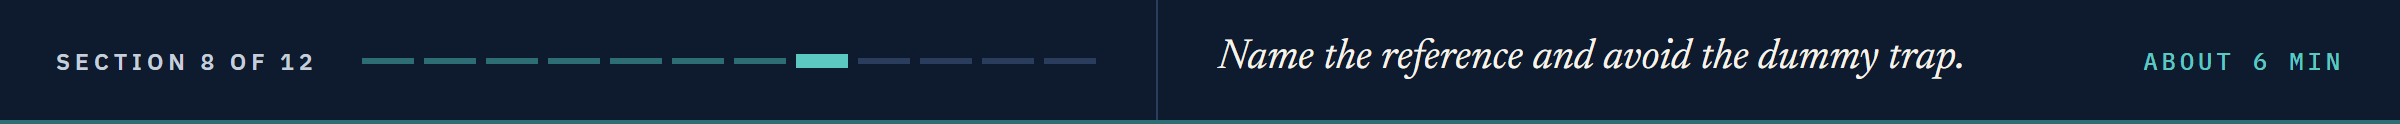

# Reading the Rating Steps

## A Step Is a Difference of Averages

Q. With the rating columns alone, no duration, what is the BBB coefficient?

In [30]:
# the 17 rating columns alone, fitted on the training bonds
model_ratings_only = LinearRegression()
model_ratings_only.fit(X_train[rating_dummies.columns], y_train)
bbb_step = pd.Series(model_ratings_only.coef_, index=rating_dummies.columns)["rating_BBB"]

# the same number from two averages: the BBB training bonds' less the A training bonds'
train_averages = y_train.groupby(train_rating).mean()
print("BBB coefficient:             ", round(bbb_step, 2))
print("BBB average minus A average: ", round(train_averages["BBB"] - train_averages["A"], 2))
print("Intercept:", round(model_ratings_only.intercept_, 2), " A average:", round(train_averages["A"], 2))

BBB coefficient:              48.99
BBB average minus A average:  48.99
Intercept: 74.6  A average: 74.6


With the rating columns alone, a step is exactly a difference of two averages, and the intercept is the reference level's average.

Add duration and the BBB step becomes 48.0 bp: the difference between a BBB and an A bond of the same duration.

## Choosing the Reference

A step is measured from the reference, so moving the reference should move the steps.

**Predict 3**

Sketch the rating steps as bars from zero, with A's bar at zero.

Now make BBB the reference instead: where does A's bar go, and do the gaps between bars change?

In [31]:
# pick a reference from the dropdown: the model is refitted without that rating's column and its steps drawn
from ipywidgets import interact

train_counts = all_ratings.loc[X_train.index].sum()

def draw_steps(reference="A"):
    X_ref = all_ratings.drop(columns="rating_" + reference).assign(duration=data["duration"])
    model_ref = LinearRegression()
    model_ref.fit(X_ref.loc[X_train.index], y_train)
    # each rating's step from the reference in bp (every coefficient but the last, duration's), the reference at 0
    steps_ref = pd.Series(model_ref.coef_[:-1], index=X_ref.columns[:-1]).reindex(all_ratings.columns, fill_value=0.0)
    plt.figure(figsize=(14, 5))
    plt.vlines(rating_order, 0, steps_ref, color="red", linewidth=2)
    plt.scatter(rating_order, steps_ref, s=train_counts * 3, color="red")  # dot size: training bonds
    plt.axhline(0, color="black")
    plt.xlabel("Rating")
    plt.ylabel("Step from " + reference + " (bp)")
    plt.title("Every Step Measured From " + reference + ": Intercept " + str(round(model_ref.intercept_, 1)) + " bp")
    plt.show()
    same = np.allclose(model_ref.predict(X_ref.loc[X_train.index]), model_steps.predict(X_train[features_steps]))
    print("Every fitted spread the same as with A as the reference:", same)

interact(draw_steps, reference=list(rating_order));

interactive(children=(Dropdown(description='reference', index=5, options=('AAA', 'AA+', 'AA', 'AA-', 'A+', 'A'…

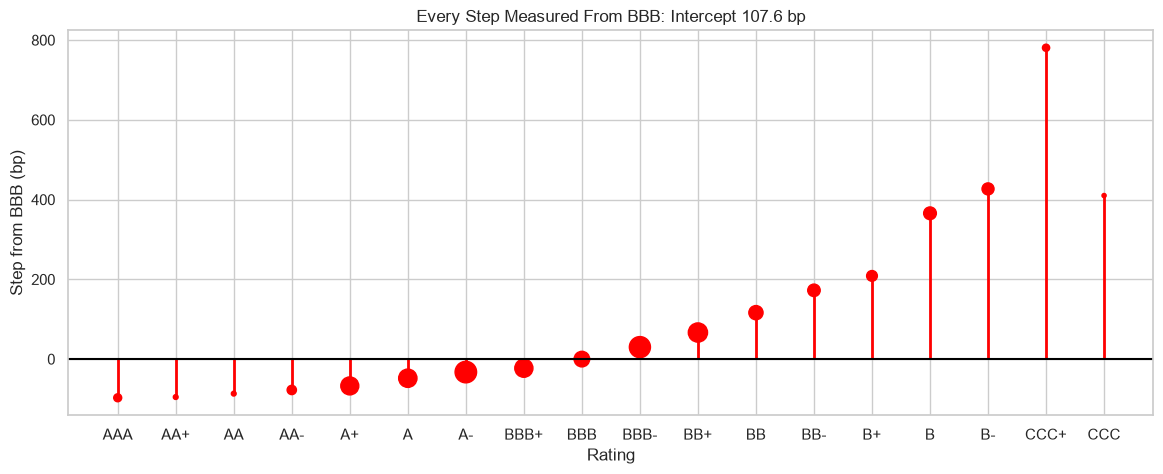

Every fitted spread the same as with A as the reference: True


In [32]:
# the dropdown set to BBB, drawn as a still picture (dropdowns do not run on GitHub)
draw_steps(reference="BBB")

With BBB as the reference, A's bar drops to -48.0 bp and the intercept rises to 107.6 bp.

The whole picture slides down by 48.0 bp; no gap between two bars changes, and neither does any fitted spread.

## Why We Name the Reference Ourselves

`pd.get_dummies(..., drop_first=True)` leaves out one level for you: the first.

Q. On the plain text column, which rating is first?

In [33]:
# the shortcut on the text column: the first four columns it keeps, how many, and their type
shortcut = pd.get_dummies(data["rating"], prefix="rating", drop_first=True)
print(list(shortcut.columns[:4]), len(shortcut.columns), "columns of", shortcut.dtypes.iloc[0])

['rating_A+', 'rating_A-', 'rating_AA', 'rating_AA+'] 17 columns of bool


The shortcut leaves out **A**, not AAA: as text, "A" sorts ahead of "A+", "AA" and "AAA".

Nothing in the code says which level went, and the columns hold True and False, not numbers.

On other bonds the first level can be another rating; Exercise 3 finds one.

**Name the reference in your own code, with `.drop(columns=...)`, and say it whenever you quote a step.**

## The Dummy Trap

Q. What happens if no level is left out?

In [34]:
# every bond has exactly one rating, so its 18 columns add up to 1
all_ratings.sum(axis=1).value_counts()

1.000    821
Name: count, dtype: int64

`.sum(axis=1)` adds across each row.

Every row sums to 1.0, which is exactly the column of ones the intercept stands for.

Keep all 18 columns and the intercept, and the model has two ways to say the same thing: the **dummy trap**.

In [35]:
# all 18 rating columns and duration, fitted on the training bonds
X_trap = all_ratings.assign(duration=data["duration"])
model_trap = LinearRegression()
model_trap.fit(X_trap.loc[X_train.index], y_train)
trap_steps = pd.Series(model_trap.coef_[:-1], index=rating_order)  # every coefficient but the last, duration's
print("Intercept:", round(model_trap.intercept_, 1), " A step:", round(trap_steps["A"], 1))
print("BB minus A:", round(trap_steps["BB"] - trap_steps["A"], 1))
print("Same fitted spreads:", np.allclose(model_trap.predict(X_trap.loc[X_train.index]), model_steps.predict(X_train[features_steps])))

Intercept: 221.6  A step: -161.9
BB minus A: 164.4
Same fitted spreads: True


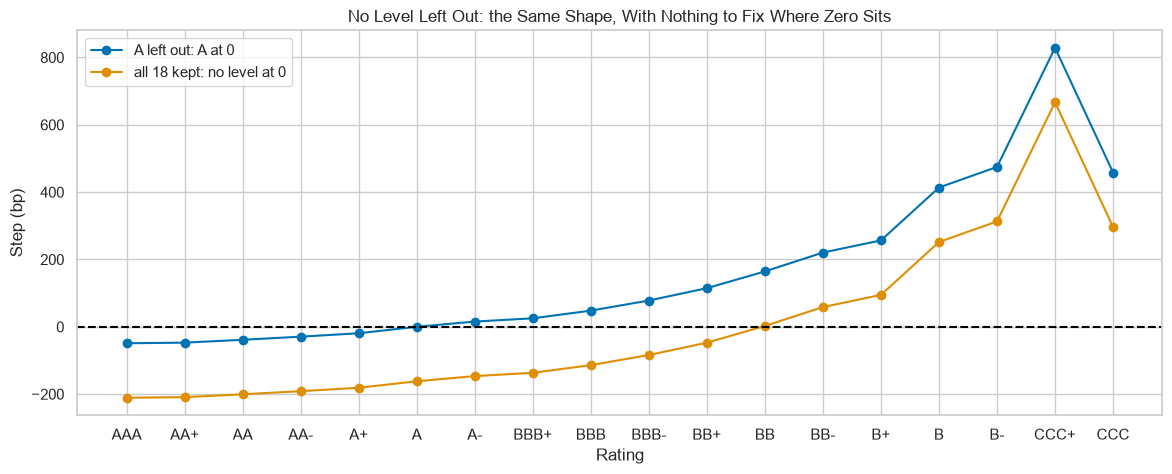

In [36]:
# the 18 steps both ways: A left out (A at 0), and all 18 kept
named_steps = coefficients[rating_dummies.columns].reindex(all_ratings.columns, fill_value=0.0)
plt.figure(figsize=(14, 5))
plt.plot(rating_order, named_steps.values, marker="o", label="A left out: A at 0")
plt.plot(rating_order, trap_steps.values, marker="o", label="all 18 kept: no level at 0")
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Rating")
plt.ylabel("Step (bp)")
plt.title("No Level Left Out: the Same Shape, With Nothing to Fix Where Zero Sits")
plt.legend()
plt.show()

The two lines are parallel, 161.9 bp apart, and every fitted spread is the same.

With no level left out, nothing fixes where zero sits, so the fit lands on one of endless equally good answers.

A difference between two steps survives, BB minus A is 164.4 bp both ways, but a single step means nothing.

**Leave one level out and name it: then every step has something to be measured from.**

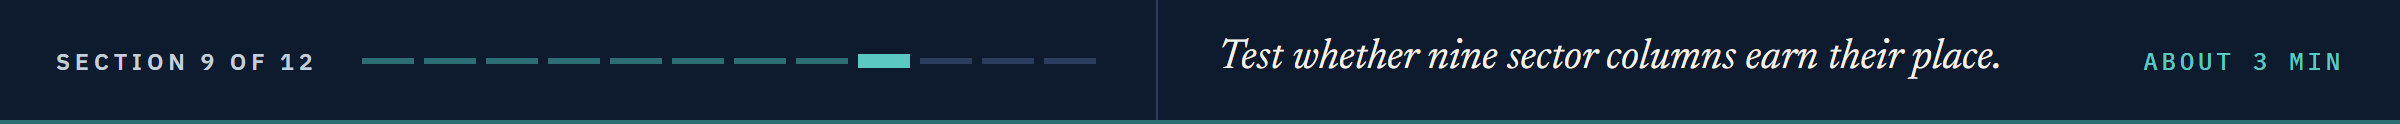

# Adding Sector

## Multiple Linear Regression - OAS vs Rating Dummies, Duration and Sector

The sector medians ran from 91 to 163.5 bp, so nine sector columns join the model.

In [37]:
# the 17 rating columns, duration, and the 9 sector columns
features_sector = features_steps + list(sector_dummies.columns)

# create the model and fit it to the training bonds
model_sector = LinearRegression()
model_sector.fit(X_train[features_sector], y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](27,)","[-37.23,-60.52,-42.88,...,-33.54,-33.33, 1.76]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](27,)","['rating_AAA','rating_AA+','rating_AA',...,'sector_Telecom', 'sector_Transportation','sector_Utilities']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,73.69
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,27
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(27)


**Predict 4**

Without sector the test MAE was 35.5 bp.

Write down the test MAE with the nine sector columns added, in bp.

In [38]:
# the sector model on training bonds, then on test bonds
sector_train_perf = model_performance_regression(model_sector, X_train[features_sector], y_train)
sector_test_perf = model_performance_regression(model_sector, X_test[features_sector], y_test)
sector_test_perf

,RMSE,MAE,MAPE,R-squared,Adj. R-squared
0,69.711,36.336,21.239,0.815,0.787


Test MAE 36.3 bp: nine more columns, and a slightly worse miss on unseen bonds.

## What the Sector Coefficients Say

The course's generator built every spread from the rating, the maturity, an issuer effect and noise.

Sector plays no part in it, so the true value of every sector coefficient is zero.

A **dumbbell chart** joins two values of one row with a line.

In [39]:
# each sector's training average less Consumer's, and its coefficient with rating and duration held fixed (bp)
sector_averages = y_train.groupby(data.loc[X_train.index, "sector"]).mean()
sector_gaps = pd.DataFrame({
    "raw gap": sector_averages.drop("Consumer") - sector_averages["Consumer"],
    "held fixed": pd.Series(model_sector.coef_, index=features_sector)[sector_dummies.columns].values,
}).sort_values("held fixed")
sector_gaps

,raw gap,held fixed
sector,,
Telecom,-46.926,-33.541
Transportation,-58.062,-33.329
Materials,-31.419,-32.146
Technology,8.796,-13.903
Health Care,-57.676,-8.888
Financials,-0.988,-8.696
Industrials,-0.910,-7.869
Energy,-0.488,-6.641
Utilities,-28.690,1.760


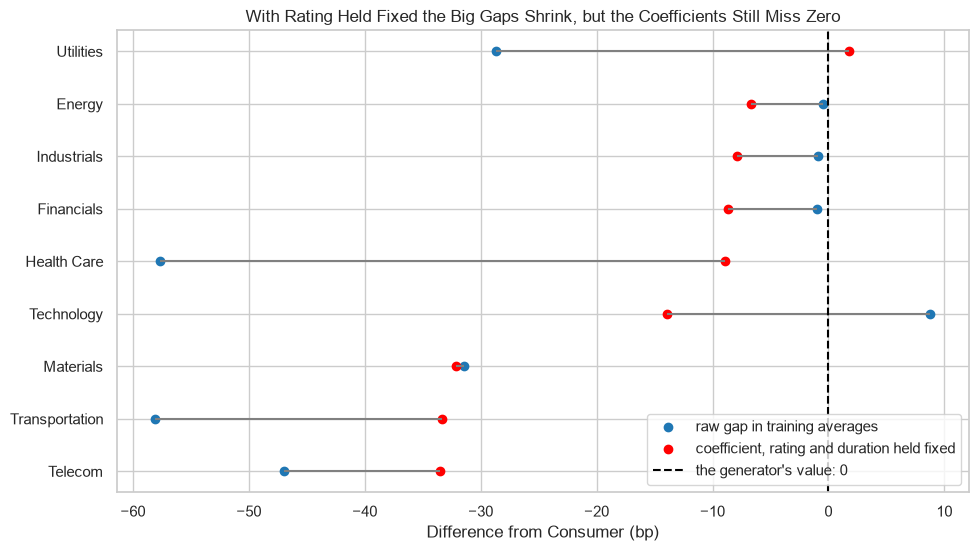

raw gap      26.000
held fixed   16.300
dtype: float64


In [40]:
# one row per sector: the raw gap, the coefficient, and a line between them
plt.figure(figsize=(11, 6))
plt.hlines(sector_gaps.index, sector_gaps["raw gap"], sector_gaps["held fixed"], color="gray")
plt.scatter(sector_gaps["raw gap"], sector_gaps.index, color="tab:blue", label="raw gap in training averages")
plt.scatter(sector_gaps["held fixed"], sector_gaps.index, color="red", label="coefficient, rating and duration held fixed")
plt.axvline(0, color="black", linestyle="--", label="the generator's value: 0")
plt.xlabel("Difference from Consumer (bp)")
plt.title("With Rating Held Fixed the Big Gaps Shrink, but the Coefficients Still Miss Zero")
plt.legend(loc="lower right")
plt.show()

# the average size of each, ignoring the sign, in bp
print(sector_gaps.abs().mean().round(1))

The coefficients run from -33.5 to 1.8 bp, and 8 of the 9 are below zero.

Holding rating and duration fixed shrinks the average size of the gaps from 26.0 to 16.3 bp: much of each raw gap was the sector's rating mix.

What is left is the issuer effects and noise of each sector's issuers, measured from Consumer's.

**Nine columns fitted to noise do slightly worse on unseen bonds, so sector stays out. Day 3 asks whether a coefficient can be told apart from zero.**

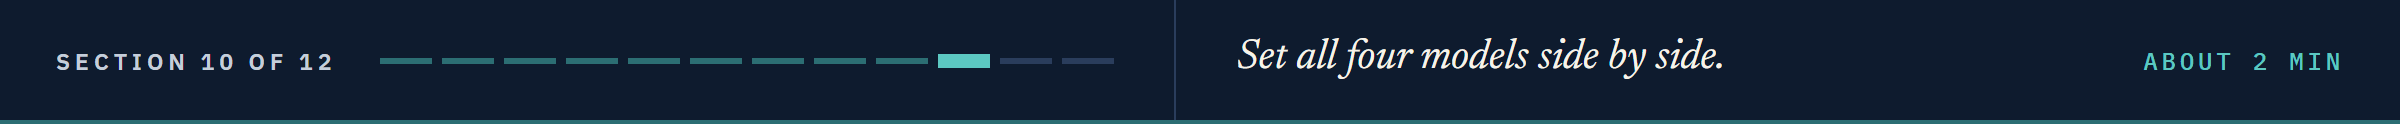

# Model Performance Comparison

Day 1's rating line, refitted, joins the table so all four models sit side by side.

In [41]:
# Day 1's line: OAS on the rating score alone
model_line = LinearRegression()
model_line.fit(X_train[["score"]], y_train)
line_train_perf = model_performance_regression(model_line, X_train[["score"]], y_train)
line_test_perf = model_performance_regression(model_line, X_test[["score"]], y_test)

## Training Performance

In [42]:
# training performance: one column per model
names = ["Day 1's line", "Score and duration", "Rating dummies and duration", "With sector"]
models_train_comp = pd.concat([line_train_perf.T, score_train_perf.T, steps_train_perf.T, sector_train_perf.T], axis=1)
models_train_comp.columns = names
models_train_comp

,Day 1's line,Score and duration,Rating dummies and duration,With sector
RMSE,133.046,133.017,110.177,109.492
MAE,65.624,65.646,42.710,44.156
MAPE,56.365,56.483,21.219,23.734
R-squared,0.523,0.523,0.673,0.677
Adj. R-squared,0.522,0.521,0.663,0.662


## Test Performance

In [43]:
# test performance: one column per model
models_test_comp = pd.concat([line_test_perf.T, score_test_perf.T, steps_test_perf.T, sector_test_perf.T], axis=1)
models_test_comp.columns = names
models_test_comp

,Day 1's line,Score and duration,Rating dummies and duration,With sector
RMSE,108.331,108.324,69.135,69.711
MAE,57.662,57.488,35.539,36.336
MAPE,42.370,42.191,19.785,21.239
R-squared,0.553,0.553,0.818,0.815
Adj. R-squared,0.551,0.549,0.800,0.787


### Interpretation of Adjusted R-squared

Training R-squared never falls when columns are added, even useless ones.

Adjusted R-squared charges for each column, and it falls twice: duration on the score, and sector on the steps.

Those are the two places the test MAE barely moves or gets worse: 57.7 to 57.5 bp, and 35.5 to 36.3 bp.

It is still a number from the training bonds, so the test bonds have the last word.

**Rating dummies and duration give the smallest typical miss on unseen bonds, 35.5 bp: we carry that model forward.**

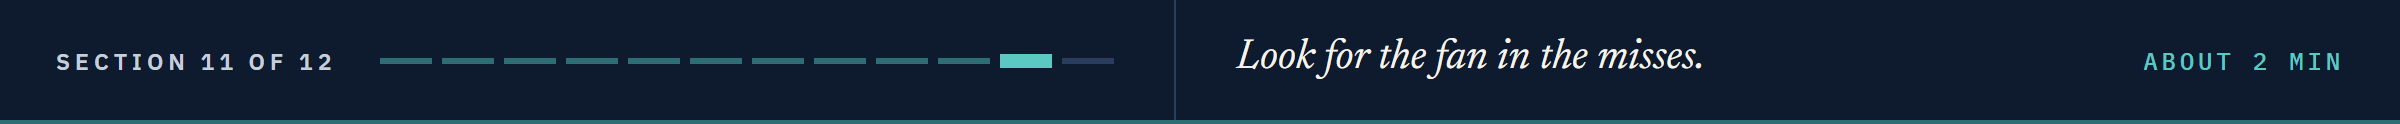

# Residual Analysis

## Residuals vs Fitted Values, Before and After

Q. Day 1's misses made a U and fanned out. What is left of each?

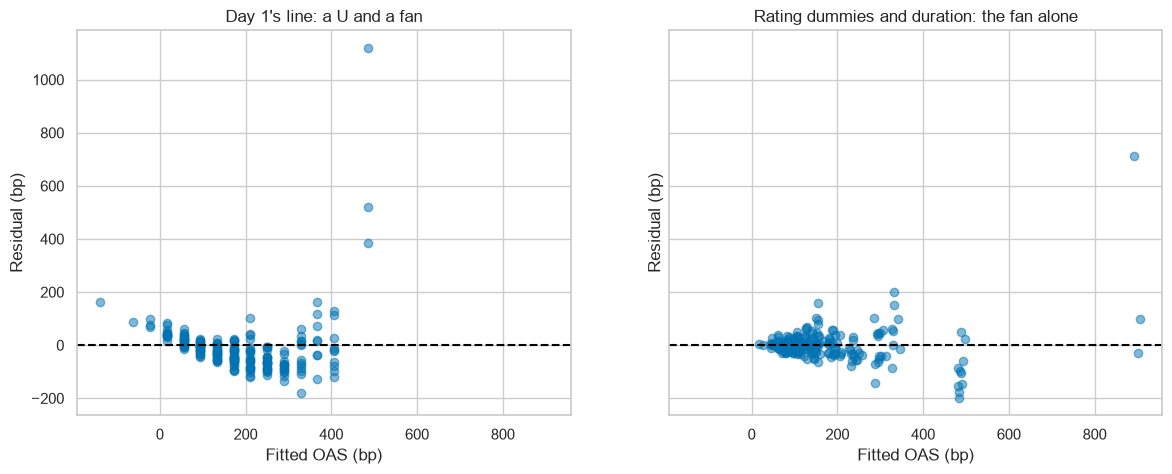

In [44]:
# each test bond's fitted spread under Day 1's line and under the steps model, in bp
fitted_line_test = model_line.predict(X_test[["score"]])
fitted_steps_test = model_steps.predict(X_test[features_steps])

# misses against fitted spread, one panel per model, on the same axes
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
axes[0].scatter(fitted_line_test, y_test - fitted_line_test, alpha=0.5)
axes[1].scatter(fitted_steps_test, y_test - fitted_steps_test, alpha=0.5)
for ax, name in zip(axes, ["Day 1's line: a U and a fan", "Rating dummies and duration: the fan alone"]):
    ax.axhline(0, color="black", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Fitted OAS (bp)")
    ax.set_ylabel("Residual (bp)")
plt.show()

In [45]:
# the test bonds the steps model misses by the most, in bp
test_bonds = data.loc[X_test.index, ["cusip", "issuer", "rating", "oas"]]
test_bonds["fitted"] = fitted_steps_test
test_bonds["residual"] = y_test - fitted_steps_test
test_bonds.sort_values("residual", ascending=False).head(3).round(1)

,cusip,issuer,rating,oas,fitted,residual
196,99038MAC3,Praxiskan Finance,CCC+,1605,892.600,712.400
393,99074WAB8,Wyxundra Energy,B+,532,332.300,199.700
210,99040OAB7,Elvizal Retail,BBB-,313,155.500,157.500


The U is gone: below high yield the misses now sit around zero at every fitted spread.

The fan stays: the wider the fitted spread, the wider the misses.

Praxiskan Finance `99038MAC3`, CCC+, is still the top dot: fitted 892.6 bp, missed by 712.4 bp (Day 1: 1,120.2).

A residual is the model's miss on one bond, not a view on the bond.

**The shape is fixed; the fan is not, because the generator scales a bond's noise with its spread. Day 4 takes logs.**

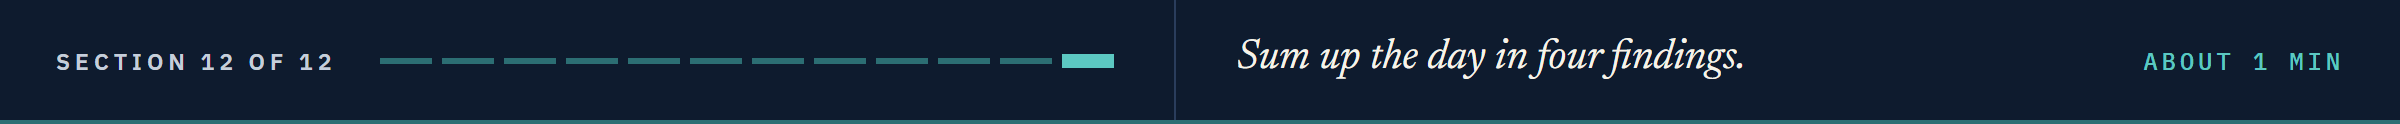

# Insights and Conclusion

Duration added to the rating score changes almost nothing in bp on unseen bonds.

Seventeen free rating steps beat one equal step: the typical test miss falls from 57.7 to 35.5 bp.

A step is a difference from the reference level you name, and the fitted spreads never depend on which one you choose.

Sector columns fitted noise and did slightly worse on unseen bonds.

**Every coefficient today was read by eye; Day 3 asks which of them can be told apart from zero.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit a multiple linear regression and read each coefficient with the other features held fixed.
* Turn a text column into dummy variables with `pd.get_dummies` and name the reference level yourself.
* Read a rating step as a difference from the reference, and change the reference without changing a fitted spread.
* Spot the dummy trap and the level `drop_first=True` leaves out.
* Compare models on test bonds with MAE, an ECDF, and adjusted R-squared.

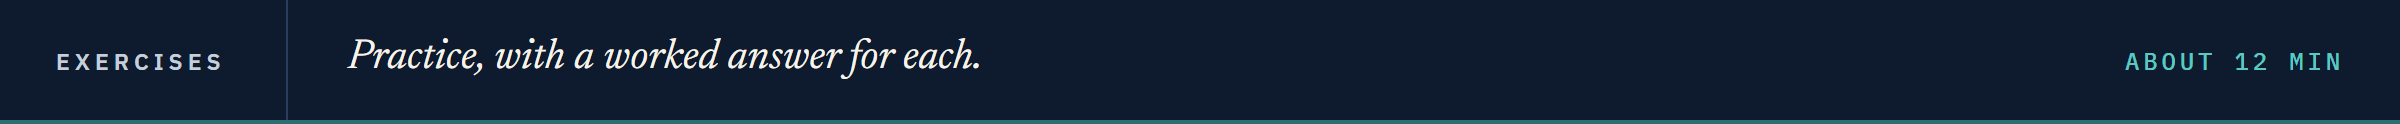

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [46]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**A Column the Generator Never Used**

Q. Add each bond's amount outstanding in billions (`amount_outstanding / 1e9`, a column named `amount_bn`) to the rating dummies and duration.
Fit on the training bonds, and store the coefficient on `amount_bn` in bp per billion in `ex1_coef` and the test MAE in bp in `ex1_test_mae_bp`.

In [47]:
# your code here
ex1_coef = ...
ex1_test_mae_bp = ...

In [48]:
check("Exercise 1 the amount coefficient", ex1_coef, -1.2538686624324669)
check("Exercise 1 the test MAE", ex1_test_mae_bp, 35.618323970375705)

Exercise 1 the amount coefficient: not attempted yet
Exercise 1 the test MAE: not attempted yet


### Exercise 2

**Investment Grade, Measured From BBB**

Q. Fit rating dummies and duration on the investment grade bonds only, with **BBB** as the reference level.
Use the investment grade levels of `ratings.csv` as the categories, `.reset_index(drop=True)` on the bonds, and the course split.
Store the `rating_AAA` coefficient in bp in `ex2_aaa_step` and the test MAE in bp in `ex2_test_mae_bp`.

In [49]:
# your code here
ex2_aaa_step = ...
ex2_test_mae_bp = ...

In [50]:
check("Exercise 2 the AAA step from BBB", ex2_aaa_step, -102.79290746432272)
check("Exercise 2 the test MAE", ex2_test_mae_bp, 20.924565657824637)

Exercise 2 the AAA step from BBB: not attempted yet
Exercise 2 the test MAE: not attempted yet


### Exercise 3

**The Level the Shortcut Left Out**

Q. Write `reference_level(columns, levels)`: it returns the first level in `levels` with no `"rating_" + level` among `columns`.
Use it on `pd.get_dummies(high_yield["rating"], prefix="rating", drop_first=True).columns`, where `high_yield` holds the high yield bonds and `levels` the high yield ratings of `ratings.csv`, and store the answer in `ex3_reference`.

In [51]:
# your code here
ex3_reference = ...

In [52]:
check("Exercise 3 the high yield reference", ex3_reference, "B")

Exercise 3 the high yield reference: not attempted yet


### Exercise 4: AI check

**The Spread Over AAA**

You asked an AI assistant for the rating steps of a rating dummies and duration model, and for the level they are measured from.

This came back.

It runs, and every coefficient is right.

In [53]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def rating_effects(bonds):
    # rating dummies and duration, fitted on the course's training bonds
    dummies = pd.get_dummies(bonds["rating"], prefix="rating", drop_first=True, dtype=float)
    features = dummies.assign(duration=bonds["duration"])
    f_train, f_test, t_train, t_test = train_test_split(features, bonds["oas"], test_size=0.25, random_state=SEED)
    model = LinearRegression()
    model.fit(f_train, t_train)
    # drop_first leaves out the first rating, AAA, so every step is the spread over AAA
    return pd.Series(model.coef_, index=features.columns), "AAA"

effects, reference = rating_effects(data)
print("Reference:", reference, "  AAA step:", round(effects["rating_AAA"], 1), "bp")

Reference: AAA   AAA step: -49.0 bp


Q. If AAA were the reference, which column could not exist?
Find the level these steps are really measured from and store it in `ex4_reference`.

In [54]:
# your code here
ex4_reference = ...

In [55]:
check("Exercise 4 the real reference", ex4_reference, "A")

Exercise 4 the real reference: not attempted yet


## Congratulations!

You built your first multiple regressions today and read every coefficient with the others held fixed.
You turned a rating into 17 columns measured from a level you named, and the typical miss on unseen bonds fell from 57.7 to 35.5 bp.
You slid every step by moving the reference without changing one fitted spread, and you sprang the dummy trap on purpose.
You caught nine sector columns fitting noise, and a shortcut that quietly measures from A.
On Day 3 you find out which of today's coefficients can be told apart from zero.

[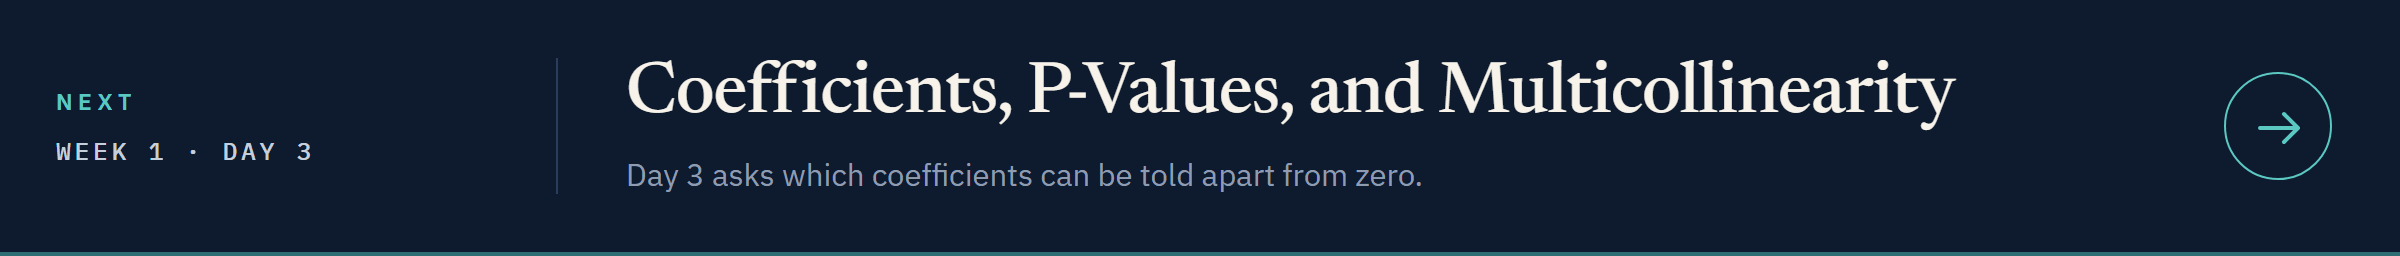](../day3/03_coefficients_p_values_and_multicollinearity.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week1/day3/03_coefficients_p_values_and_multicollinearity.ipynb)